# Lab 10: Ensemble Methods
### COMM 4259 <br> <i>Foundations of Machine Learning and AI</i>

© Jingjing Li- Ask for permission for using/quoting: jingjing.li@virginia.edu


## Lab Prep
* If you would like to see my screen on your computer, you can use a web browser to log in to Zoom, turn off the speaker and mute yourself.
    - Section 001, 11:00 a.m. – 12:15 p.m.: https://mcintire.zoom.us/j/95993311893?pwd=NmabjMgwCFyKkxzib3qMFahEDkkaSI.1
    - Section 002, 2:00 – 3:15 p.m.: https://mcintire.zoom.us/j/97629389481?pwd=GA37uPdbfC0154k4M3n17SGf6qaYCg.1
* Have VS Code open with your `comm4259-work` folder before we start.

## Lab Rules
* Raise hands for questions
* Be prepared to share your screen for Q & A or exercises

# Before You Start: Save the Lab Files to GitHub
1. Download `lab_10.zip` from Canvas, move it into your `comm4259-work` folder, and unzip it there. You now have `comm4259-work/lab_10/` with this notebook and its data.
2. In VS Code, open `comm4259-work` and a terminal (Terminal > New Terminal). From `comm4259-work`, commit and push the files you just downloaded:

```
git add .
git commit -m "Lab 10: downloaded the lab files"
git push
```

Your repository now has the starting copy, and your commit at the end of class shows the work you did in the lab.

# Learning Objectives
In this lab we will learn several ensemble methods:
- Bagging 
- Random Forest
- Boosting: AdaBoost and XGBoost
- Voting
- Stacking
- Claude Code: see what fills the context window, test what the agent remembers between sessions, and map both with a course skill.


# Data Set
- WineQuality.csv


# Check XGBoost
Run the cell below. It should print a version number, such as `3.1.1`. If it shows an error instead, try these fixes in order, and run the cell again after each one.

1. **`No module named 'xgboost'`: check the kernel first.** Click **Select Kernel** at the top right of the notebook and choose **base (anaconda3)**. The other packages in this lab are in that environment too.
2. **Still `No module named 'xgboost'`: install it.** In the next cell, remove the `#` in front of `%pip install xgboost` and run that cell. `%pip` installs into the kernel this notebook is using, so it reaches the right environment. When it finishes, restart the kernel (**Restart** in the toolbar), then run the check cell again.
3. **Mac only: an `XGBoostError` that mentions `libomp.dylib`.** XGBoost is installed, but your Mac is missing the OpenMP library that it needs. In the next cell, remove the `#` in front of `%conda install` and run it, then restart the kernel and run the check cell again.
4. **Still not working:** ask a TA, and keep going with the rest of the lab. The import cell below skips XGBoost when it is missing, so every other model still runs. Only the XGBoost section and its row in the summary table are left out.

In [1]:
import xgboost
print(xgboost.__version__)

3.1.1


In [2]:
# Only if the check above failed. Remove the # in front of ONE line, run this cell, then restart the kernel.
# %pip install xgboost                                 # step 2: No module named 'xgboost'
# %conda install -y -c conda-forge llvm-openmp         # step 3 (Mac): error mentions libomp.dylib

# Import libraries
Sklearn contains multiple ensemble classes in **sklearn.ensemble**:
- Bagging: **BaggingClassifier**
- Random Forests: **RandomForestClassifier**
- Boosting: **AdaBoostClassifier** (sklearn) and **XGBClassifier** (from the xgboost library)
- Voting: **VotingClassifier**
- Stacking: **StackingClassifier**


In [3]:
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt
%precision 4

from scipy.stats import uniform, randint

# Ensemble Methods
from sklearn.ensemble import BaggingClassifier, RandomForestClassifier
from sklearn.ensemble import AdaBoostClassifier
from sklearn.ensemble import VotingClassifier, StackingClassifier

# XGBoost (skipped if it is not installed; see Check XGBoost above)
try:
    from xgboost import XGBClassifier
except Exception:
    XGBClassifier = None
    print("XGBoost is not available, so the XGBoost cells will be skipped. See Check XGBoost above.")

#  Classifiers
from sklearn.tree import DecisionTreeClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC, SVC

# Evaluation 
from sklearn.metrics import accuracy_score, confusion_matrix # accuracy and confusion matrix
from sklearn.metrics import precision_score, recall_score, f1_score, classification_report # precision, recall, and f1
from sklearn.metrics import roc_auc_score # roc and auc

# Pipeline and preprocessing
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures, MinMaxScaler

# Model Selection
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, train_test_split
from sklearn.feature_selection import SelectKBest, chi2, mutual_info_classif

# Ignore useless warnings (see SciPy issue #5998)
import warnings
warnings.filterwarnings("ignore")
import sklearn
print(sklearn.__version__)

1.5.1


# Exploratory Data Analysis & Data Preparation

## Obtain dataset info

In [4]:
# Read the .csv file and store it as a pandas DataFrame
wine = pd.read_csv("WineQuality.csv")

# Get the shape
print("Data shape (rows, cols):")
print(wine.shape)

# Get the column types
print("\nFeature types:")
print(wine.dtypes)

# Get the missing values
print("\nMissing info:")
print(wine.isna().sum())

# View the data
wine.head()

Data shape (rows, cols):
(2700, 12)

Feature types:
fixed acidity           float64
volatile acidity        float64
citric acid             float64
residual sugar          float64
chlorides               float64
free sulfur dioxide     float64
total sulfur dioxide    float64
density                 float64
pH                      float64
sulphates               float64
alcohol                 float64
quality                  object
dtype: object

Missing info:
fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,8.0,0.45,0.36,8.8,0.026,50.0,151.0,0.99270,3.07,0.25,12.7,Good
1,8.3,0.21,0.41,2.2,0.050,24.0,108.0,0.99400,2.85,0.45,9.5,Poor
2,7.6,0.27,0.29,2.5,0.059,37.0,115.0,0.99328,3.09,0.37,9.8,Poor
3,6.0,0.18,0.31,1.4,0.036,14.0,75.0,0.99085,3.34,0.58,11.1,Good
4,7.0,0.14,0.28,1.3,0.026,10.0,56.0,0.99352,3.46,0.45,9.9,Poor


## Examine class label

quality
Poor    0.607407
Good    0.392593
Name: count, dtype: float64


<Axes: xlabel='quality', ylabel='count'>

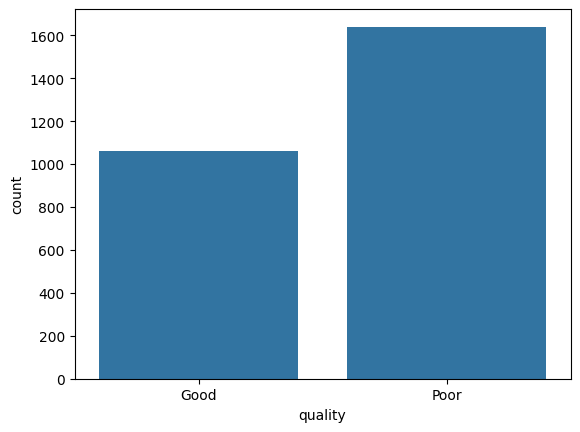

In [5]:
print(wine.quality.value_counts()/wine.quality.count())
sns.countplot(x = wine.quality)

## Transform class labels to be 0 and 1 
This is especially useful for logistic regression models

In [6]:
wine.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,8.0,0.45,0.36,8.8,0.026,50.0,151.0,0.99270,3.07,0.25,12.7,Good
1,8.3,0.21,0.41,2.2,0.050,24.0,108.0,0.99400,2.85,0.45,9.5,Poor
2,7.6,0.27,0.29,2.5,0.059,37.0,115.0,0.99328,3.09,0.37,9.8,Poor
3,6.0,0.18,0.31,1.4,0.036,14.0,75.0,0.99085,3.34,0.58,11.1,Good
4,7.0,0.14,0.28,1.3,0.026,10.0,56.0,0.99352,3.46,0.45,9.9,Poor


In [7]:
wine['quality'] = wine.quality.map({'Good':1, 'Poor':0})
print(wine.quality.value_counts()/wine.quality.count())
wine.head()

quality
0    0.607407
1    0.392593
Name: count, dtype: float64


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,8.0,0.45,0.36,8.8,0.026,50.0,151.0,0.99270,3.07,0.25,12.7,1
1,8.3,0.21,0.41,2.2,0.050,24.0,108.0,0.99400,2.85,0.45,9.5,0
2,7.6,0.27,0.29,2.5,0.059,37.0,115.0,0.99328,3.09,0.37,9.8,0
3,6.0,0.18,0.31,1.4,0.036,14.0,75.0,0.99085,3.34,0.58,11.1,1
4,7.0,0.14,0.28,1.3,0.026,10.0,56.0,0.99352,3.46,0.45,9.9,0


## Separate data into input features and class labels

In [8]:
# Define class labels
target_name = "quality"

# Create a dataframe for input attributes
X = wine.drop(target_name, axis = 1)

# Create a dataframe for class labels
y = wine[target_name]

# Obtain attribute(feature) names (used for tree visualization)
fnames = list(X.columns)
print(fnames)

# Obtain the index (row identifier)
findex = X.index

# Obtain class label names
cnames = np.sort(y.unique())
# Convert the class names to strings (used for plots)
cnames = [str(x) for x in cnames] 

print(cnames)

['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol']
['0', '1']


## Standardize features
Standardize features by removing the mean and scaling to unit variance.
The standard score of a sample x is calculated as:
\begin{equation}
\frac{(x-\mu)}{\sigma}
\end{equation}
The scaler learns the mean and standard deviation from the **training data only**, and then applies the same values to the test data, just as SimpleImputer did in Lab 05/06. So we standardize right after splitting the data, in the next section.

In [9]:
# The scaler is fitted after the train/test split below, on the training data only
scaler = StandardScaler()

# Modeling and Evaluation

In this step, we will split the dataset into training and test sets, and conduct a cross validation on the training data to select the best model parameters. Finally, we apply the model with the best parameters to the test data for evaluation.

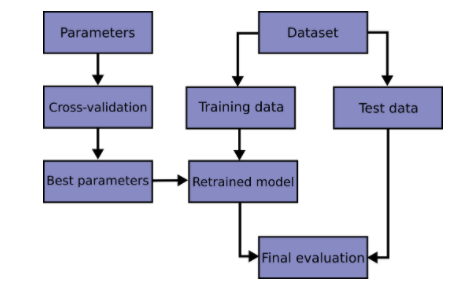

## Split the data into training and test

In [10]:
X_train, X_test, y_train, y_test = train_test_split(X, y,
                                                  test_size = 0.2, #20% for testing and 80% for training
                                                  random_state = 1, 
                                                  stratify = y) # Make sure class label distributions are comparable

# Standardize: learn the mean and standard deviation from the training data only
X_train = pd.DataFrame(scaler.fit_transform(X_train), columns = fnames, index = X_train.index)
X_test = pd.DataFrame(scaler.transform(X_test), columns = fnames, index = X_test.index)
X_train.describe()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol
count,2.160000e+03,2.160000e+03,2.160000e+03,2.160000e+03,2.160000e+03,2.160000e+03,2.160000e+03,2.160000e+03,2.160000e+03,2.160000e+03,2.160000e+03
mean,1.628327e-16,3.914564e-16,-4.358653e-17,4.769847e-17,2.763222e-16,1.019760e-16,-9.046262e-17,3.714724e-15,-1.644775e-17,-3.684296e-16,-6.085667e-17
std,1.000232e+00,1.000232e+00,1.000232e+00,1.000232e+00,1.000232e+00,1.000232e+00,1.000232e+00,1.000232e+00,1.000232e+00,1.000232e+00,1.000232e+00
min,-3.479328e+00,-1.990920e+00,-2.693353e+00,-1.145665e+00,-1.564915e+00,-1.770796e+00,-3.027401e+00,-2.340798e+00,-2.664674e+00,-2.319905e+00,-1.897600e+00
25%,-6.649201e-01,-6.782400e-01,-5.750618e-01,-9.242252e-01,-4.394822e-01,-6.734627e-01,-6.966299e-01,-7.864387e-01,-6.577132e-01,-6.818742e-01,-8.148545e-01
50%,-7.858517e-02,-1.156626e-01,-1.676981e-01,-2.397762e-01,-1.477034e-01,-6.992958e-02,-8.509089e-02,-9.186590e-02,-5.562502e-02,-1.646013e-01,-1.961426e-01
75%,6.250168e-01,4.469148e-01,4.840839e-01,6.711450e-01,1.857581e-01,5.884702e-01,6.879867e-01,7.384183e-01,6.133619e-01,4.388837e-01,7.319251e-01
max,4.025760e+00,7.572895e+00,5.453921e+00,3.283123e+00,1.248215e+01,1.392107e+01,6.918761e+00,2.811179e+00,4.225891e+00,5.094339e+00,2.897417e+00


# Ensemble
Ensemble is a technique that combines the predictions from multiple machine learning models to make better predictions. It works better if base classifiers are independent.

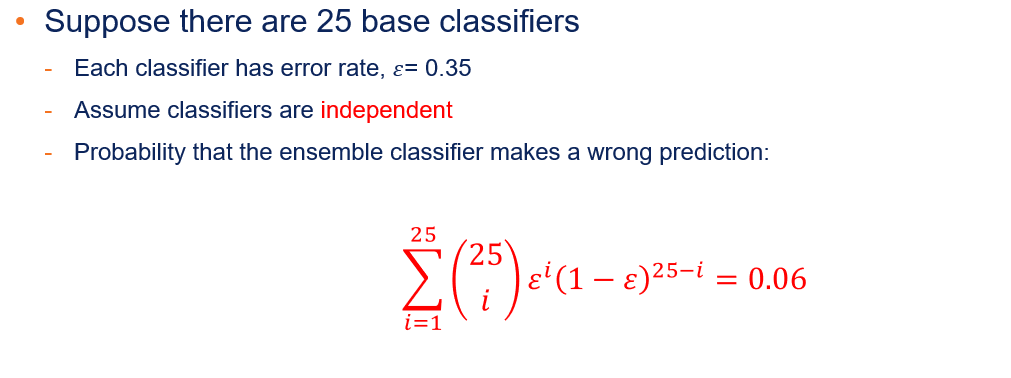

## Voting

A very simple way to create an even better classifier is to aggregate the predictions of each classifier and predict the class that gets the most votes. This majority-vote classifier is called a hard voting classifier. This voting classifier often achieves a higher accuracy than the best classifier in the ensemble.


[sklearn.ensemble.VotingClassifier Documentation](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.VotingClassifier.html)

### Majority Vote

In [11]:
# define individual classifier (maximize differences)
dt = DecisionTreeClassifier(max_depth = 15, 
                            random_state = 1)
nn = MLPClassifier(hidden_layer_sizes = (100, 150, 100), 
                   alpha = 0.0001, # L2 penalty (regularization term) parameter
                   max_iter = 1000,
                   activation = 'relu', 
                   learning_rate = "adaptive",
                   learning_rate_init = 0.1,
                   random_state = 1)
knn = KNeighborsClassifier(n_neighbors = 5, 
                           metric='euclidean')
lreg = LogisticRegression(random_state = 1)
#lreg = Pipeline([('poly_features', PolynomialFeatures(degree = 2)), ('logistic_regression', LogisticRegression(random_state = 42))])

svm = SVC(C = 1, 
          kernel = 'rbf', 
          gamma = 0.1,
          random_state = 42,
          probability = True)

# create an estimator
classifiers = [('decisionTree', dt),
               ('neuralNet', nn),
               ('neighbor', knn),
               ('logistic', lreg),
               ('svm', svm)]

# train
voting_clf = VotingClassifier(estimators = classifiers, 
                              voting = 'hard')
voting_clf.fit(X_train, y_train)


# test
y_test_vh = voting_clf.predict(X_test)
acc_vh = accuracy_score(y_test, y_test_vh)

print(f"The test data performance for Voting (hard) is {acc_vh:.2%}")
print(classification_report(y_test, y_test_vh, digits = 4))

The test data performance for Voting (hard) is 88.70%
              precision    recall  f1-score   support

           0     0.9159    0.8963    0.9060       328
           1     0.8447    0.8726    0.8585       212

    accuracy                         0.8870       540
   macro avg     0.8803    0.8845    0.8822       540
weighted avg     0.8880    0.8870    0.8873       540



In [12]:
# Check the individual classifier
for label, clf in classifiers:
    clf.fit(X_train, y_train)
    y_pred = clf.predict(X_test)
    print(label, accuracy_score(y_test, y_pred))

decisionTree 0.85


neuralNet 0.8611111111111112
neighbor 0.8555555555555555
logistic 0.8111111111111111


svm 0.8703703703703703


### Weighted Vote
However, voting can sometimes give **lower accuracy**, since the classifiers may not be perfectly independent and make correlated errors. Hence, majority votes may be wrong. One solution is to use the **soft** voting mechanism and assign **weights** to each classifier.

In [13]:
# use the classifiers defined in Majority Vote code cell

# train
votsoft_clf = VotingClassifier(estimators = classifiers, 
                               voting = 'soft', weights = (1,2,1,1,2))

votsoft_clf.fit(X_train, y_train)

# test
y_test_vs = votsoft_clf.predict(X_test)
acc_vs = accuracy_score(y_test, y_test_vs)

print(f"The test data performance for Voting (soft) is {acc_vs:.2%}")
print(classification_report(y_test, y_test_vs, digits = 4))

The test data performance for Voting (soft) is 87.96%
              precision    recall  f1-score   support

           0     0.9071    0.8933    0.9002       328
           1     0.8387    0.8585    0.8485       212

    accuracy                         0.8796       540
   macro avg     0.8729    0.8759    0.8743       540
weighted avg     0.8803    0.8796    0.8799       540



## Stacking

Stacking is a technique that takes several regression or classification models and uses their output as the input for the meta-classifier/regressor.

[sklearn.ensemble.StackingClassifier Documentation](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.StackingClassifier.html)

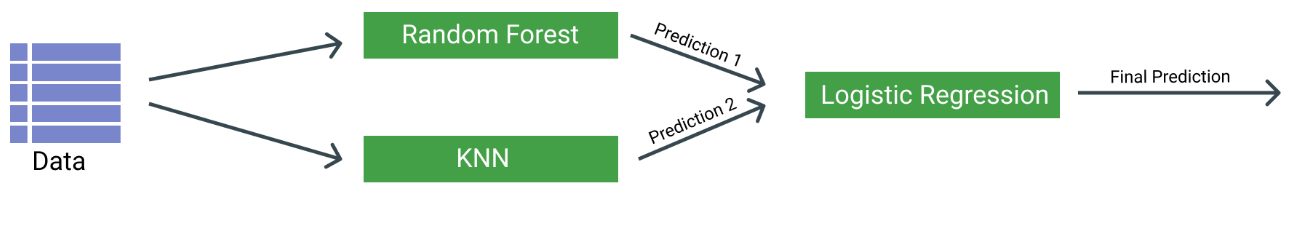

In [14]:
# use the classifiers defined in Majority Vote code cell

# train
stack_clf = StackingClassifier(estimators = classifiers,
                               final_estimator = LogisticRegression()) # final predictor

stack_clf.fit(X_train, y_train)

# test
y_test_sk = stack_clf.predict(X_test)
acc_sk = accuracy_score(y_test, y_test_sk)

print(f"The test data performance for Stacking is {acc_sk:.2%}")
print(classification_report(y_test, y_test_sk, digits = 4))

The test data performance for Stacking is 88.15%
              precision    recall  f1-score   support

           0     0.9049    0.8994    0.9021       328
           1     0.8458    0.8538    0.8498       212

    accuracy                         0.8815       540
   macro avg     0.8754    0.8766    0.8760       540
weighted avg     0.8817    0.8815    0.8816       540



## Exercise 1
<div style="background-color:#DFF5DC; color:#14532D; border:1px solid #A5D6A7; border-left:5px solid #2E7D32; padding:15px; margin-bottom:20px; border-radius:4px;">
Using Majority Vote, we obtained an accuracy of 88.70%.
    
The following code uses a pipeline object to build a logistic regression with polynomial features (degree = 2). Replace the logistic regression lreg in the 
Majority Vote Section with this pipeline code and obtain the new accuracy. 
   
Why do accuracies increase/decrease?
    </div>

```python
lreg = Pipeline([('poly_features', PolynomialFeatures(degree = 2)), ('logistic_regression', LogisticRegression(random_state = 42))])
```

# Tree-based Ensemble
Decision tree is one of the most widely used classifiers in practice. Hence, several ensemble methods are designed around it. The following chart is the evolution of tree-based algorithms.
- Bagging
- Random Forest
- Boosting (Adaboosting)
- Gradient Boosting
- XGBoost


Nowadays, XGBoost is considered to be best-in-class. This ensemble model has not only been credited with winning numerous Kaggle competitions but also for being the driving force under the hood for several cutting-edge industry applications. 

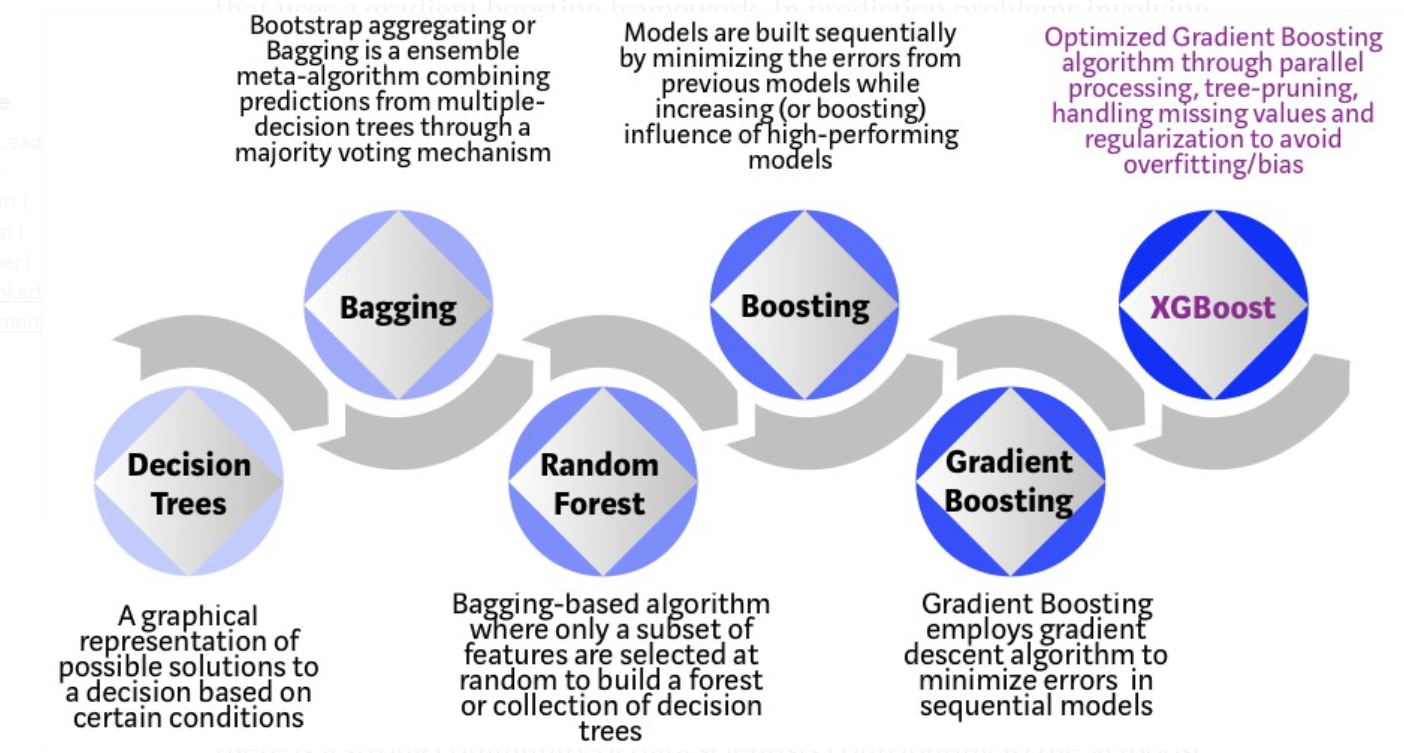

## Bagging

Bagging is short for Bootstrap AGGregation. It improves the stability and accuracy of machine learning algorithms. It also reduces variance and helps avoid overfitting.
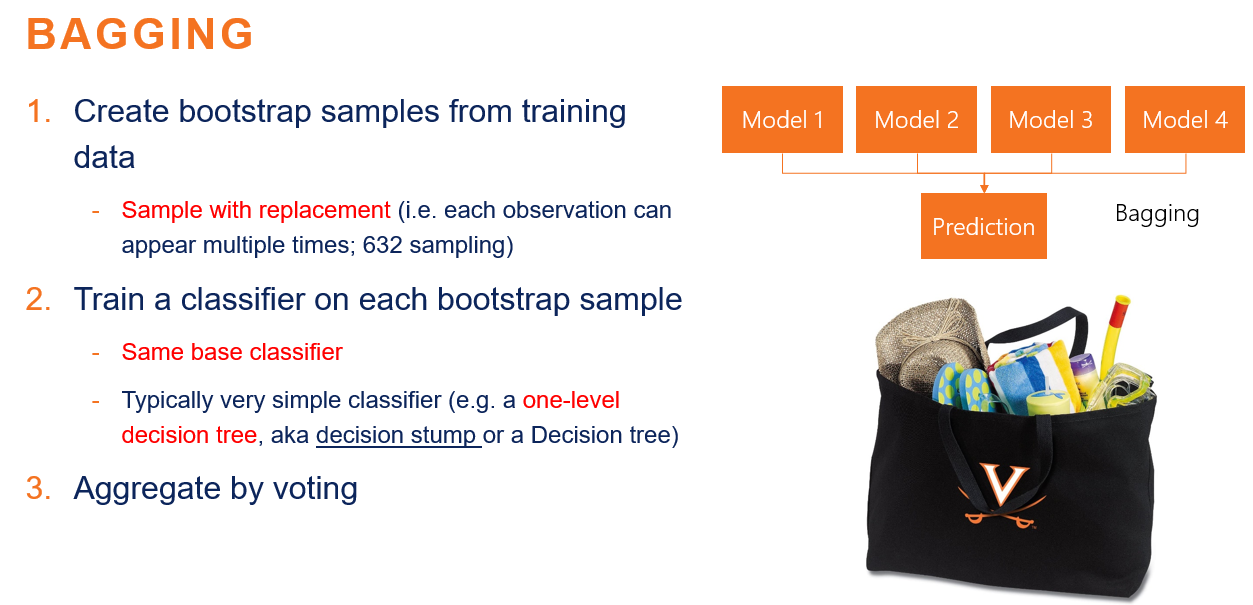

<!--- <img src = 'https://miro.medium.com/max/1920/1*DFHUbdz6EyOuMYP4pDnFlw.jpeg' width = '700'> --->

[sklearn.ensemble.BaggingClassifier Documentation](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.BaggingClassifier.html)


In [15]:
# train
bag_clf = BaggingClassifier(estimator = DecisionTreeClassifier(max_depth = 10, random_state  = 1),
                            n_estimators = 100, 
                            random_state = 1)
bag_clf.fit(X_train, y_train)

# test
y_test_bag = bag_clf.predict(X_test)
acc_bag = accuracy_score(y_test, y_test_bag)

print(f"The test data performance for Bagging is {acc_bag:.2%}")
print(classification_report(y_test, y_test_bag, digits = 4))

The test data performance for Bagging is 90.37%
              precision    recall  f1-score   support

           0     0.9313    0.9085    0.9198       328
           1     0.8636    0.8962    0.8796       212

    accuracy                         0.9037       540
   macro avg     0.8974    0.9024    0.8997       540
weighted avg     0.9047    0.9037    0.9040       540



In [16]:
# create a dataframe to store features names and the importance
bag_imp = pd.DataFrame(list(zip(X_train.columns, np.mean([
    tree.feature_importances_ for tree in bag_clf.estimators_
], axis=0))), columns = ['feature', 'bag_imp_score']).sort_values(by = 'bag_imp_score', ascending = False)
bag_imp

,feature,bag_imp_score
10,alcohol,0.421829
1,volatile acidity,0.121392
5,free sulfur dioxide,0.095223
3,residual sugar,0.060717
8,pH,0.050257
4,chlorides,0.046569
9,sulphates,0.043924
0,fixed acidity,0.042660
7,density,0.041275
6,total sulfur dioxide,0.041016


## Random Forest

Random Forests are an improvement over bagged decision trees. Decision Trees choose which variable to split on using a greedy algorithm that minimizes error. Even with Bagging, the decision trees can have a lot of structural similarities and in turn have high correlation in their predictions. Random forest's sub-trees are based on different subsets of features. Hence, the trees are less correlated.

- Parameters:
    - n_estimators: the number of trees to build
    - max_features: The number of features to consider when looking for the best split
    - other parameters: same as decision tree (e.g., minimal gain, maximal depth)
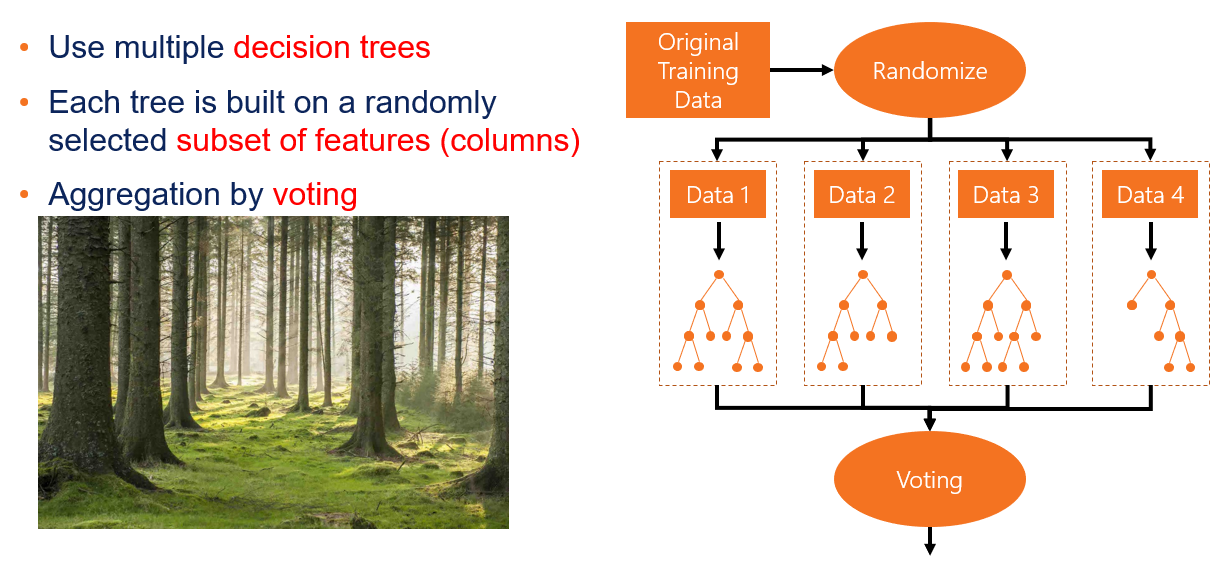


[sklearn.ensemble.RandomForestClassifier Documentation](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html)

In [17]:
# train
rf_clf = RandomForestClassifier(max_depth = 15, max_features = 0.9, 
                                n_estimators = 100,
                                random_state = 1)
rf_clf.fit(X_train, y_train)

# test
y_test_rf = rf_clf.predict(X_test)
acc_rf = accuracy_score(y_test, y_test_rf)

print(f"The test data performance for Random Forest is {acc_rf:.2%}")
print(classification_report(y_test, y_test_rf, digits = 4))

The test data performance for Random Forest is 91.11%
              precision    recall  f1-score   support

           0     0.9375    0.9146    0.9259       328
           1     0.8727    0.9057    0.8889       212

    accuracy                         0.9111       540
   macro avg     0.9051    0.9101    0.9074       540
weighted avg     0.9121    0.9111    0.9114       540



### Feature Importance

In [18]:
# create a dataframe to store features names and the importance
rf_imp = pd.DataFrame(list(zip(X_train.columns, rf_clf.feature_importances_)), 
                     columns = ['feature', 'rf_imp_score']).sort_values(by = 'rf_imp_score', ascending = False)
rf_imp

,feature,rf_imp_score
10,alcohol,0.331713
1,volatile acidity,0.114981
7,density,0.108823
5,free sulfur dioxide,0.092204
3,residual sugar,0.064068
4,chlorides,0.060941
8,pH,0.051579
0,fixed acidity,0.045681
9,sulphates,0.045548
6,total sulfur dioxide,0.044837


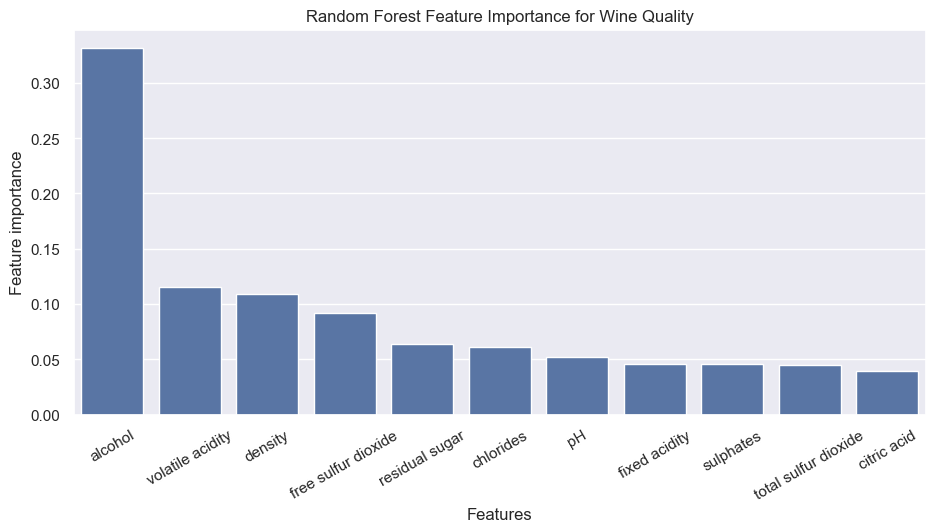

In [19]:
# set figure size
sns.set(rc={'figure.figsize':(11,5)})
ax = sns.barplot(x = 'feature', y = 'rf_imp_score', data = rf_imp)
ax.set_title('Random Forest Feature Importance for Wine Quality')
ax.set(ylabel='Feature importance')
ax.set(xlabel='Features')
ax.set_xticklabels(ax.get_xticklabels(), rotation = 30); # rotate x label

## AdaBoosting
Boosting trains models sequentially. The latter model corrects the errors generated by former models. In each iteration, Boosting identifies misclassified data points, increasing their weights (and decreasing the weights of correct points, in a sense) so that the next classifier will pay extra attention to get them right. 
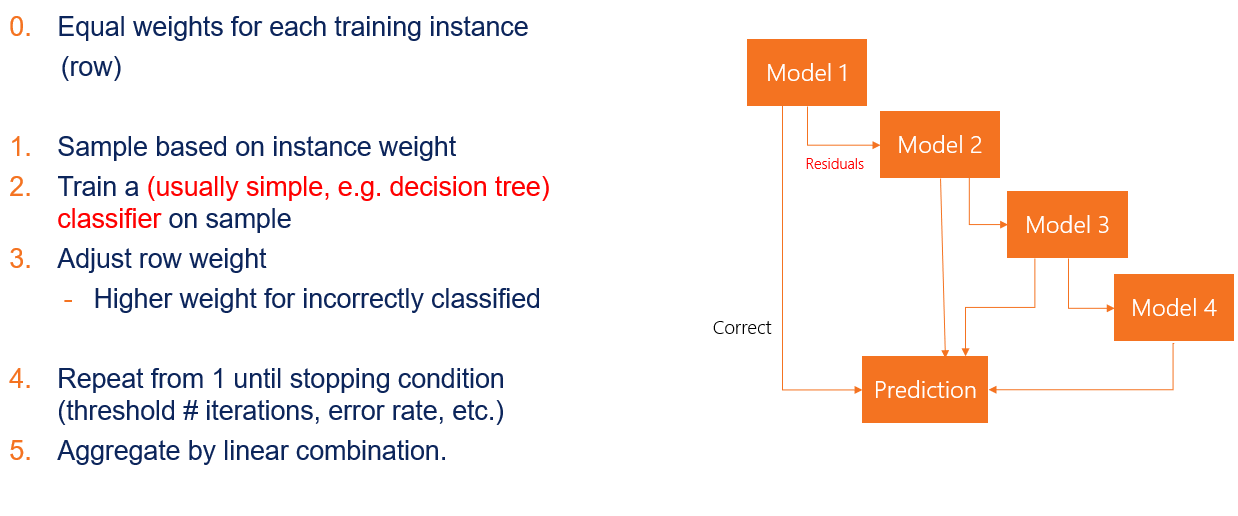



[sklearn AdaBoost documentation](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.AdaBoostClassifier.html)
<!--- comment

If you are interested in learning more about AdaBoost, please watch [this video](https://www.youtube.com/watch?v=LsK-xG1cLYA).
 amount of say : the weight used in voting in the final classification result = 
$\frac{1}{2}\times log (\frac{1 - Total Error probability}{Total Error probability})$

weight: the weight used when bootstrapping new dataset<br>

$$sample\space weight(misclassification\space data) = sample\space weight \times e^{amount of say}$$

$$sample\space weight(correctly classification\space data) = sample\space weight \times e^{-amount of say}$$

**Ada Boosting Process:**

1. initial weight by $\frac{1}{Total sample}$
2. Choose the best split using Gini impurity
3. Calculate the amount of say by the chosen split
4. Calculate the new sample weight 
5. Continue using weighted Gini index to emphasize correctly classifying large-weight samples (misclassified data) or using bootstrap to get new dataset from original dataset. Misclassification data will have more chance to be selected and may be selected many times. 
6. Start the same process from step 1
7. After iterating many times, the final classification result will be based on the larger amount of say class. 

--->

In [20]:
# train
ada_clf = AdaBoostClassifier(estimator = DecisionTreeClassifier(max_depth = 15, 
                            random_state = 1), n_estimators = 100, 
                             #algorithm = "SAMME",
                             random_state = 1)
ada_clf.fit(X_train, y_train)

# test
y_test_ada = ada_clf.predict(X_test)
acc_ada = accuracy_score(y_test, y_test_ada)

print(f"The test data performance for Adaboost is {acc_ada:.2%}")
print(classification_report(y_test, y_test_ada, digits = 4))

The test data performance for Adaboost is 90.37%
              precision    recall  f1-score   support

           0     0.9233    0.9177    0.9205       328
           1     0.8738    0.8821    0.8779       212

    accuracy                         0.9037       540
   macro avg     0.8986    0.8999    0.8992       540
weighted avg     0.9039    0.9037    0.9038       540



**Your AdaBoost accuracy may differ from the one shown here.** scikit-learn 1.6 removed AdaBoost's old default algorithm (SAMME.R) and now always uses SAMME. On scikit-learn 1.5 or earlier this cell scores about 90%; on 1.6 or later, about 86%. Check your version with `sklearn.__version__`. Neither result is wrong, and the other models in this lab are not affected.

Discussion about adaboost NaN: https://github.com/scikit-learn/scikit-learn/discussions/20315

In [21]:
# create a dataframe to store features names and the importance
ada_imp = pd.DataFrame(list(zip(X_train.columns, ada_clf.feature_importances_)), 
                     columns = ['feature', 'ada_imp_score']).sort_values(by = 'ada_imp_score', ascending = False)
ada_imp

,feature,ada_imp_score
6,total sulfur dioxide,0.200329
10,alcohol,0.187300
4,chlorides,0.127503
5,free sulfur dioxide,0.120962
1,volatile acidity,0.111600
7,density,0.065649
9,sulphates,0.057089
3,residual sugar,0.045760
0,fixed acidity,0.035689
8,pH,0.032969


## XGBoost

XGBoost algorithm was developed as a research project at the University of Washington. Tianqi Chen and Carlos Guestrin presented their paper at SIGKDD Conference in 2016 and took the machine learning world by storm. Since its introduction, this algorithm has not only been credited with winning numerous Kaggle competitions but also for being the driving force under the hood for several cutting-edge industry applications. As a result, there is a strong community of data scientists contributing to the XGBoost open source project on GitHub. The algorithm differentiates itself in the following ways:
- A wide range of applications: Can be used to solve regression, classification, ranking, and user-defined prediction problems.
- Portability: Runs smoothly on Windows, Linux, and macOS.
- Languages: Supports all major programming languages including C++, Python, R, Java, Scala, and Julia.
- Cloud Integration: Supports AWS, Azure, and Yarn clusters and works well with Flink, Spark, and other ecosystems.

[XGBoost Documentation](https://xgboost.readthedocs.io/en/latest/)
[XGBoost Parameter Tuning](https://www.analyticsvidhya.com/blog/2016/03/complete-guide-parameter-tuning-xgboost-with-codes-python/)

In [22]:
if XGBClassifier is None:
    acc_xg = float("nan")   # no XGBoost score; this row is left blank in the summary table
    print("XGBoost is not installed. See Check XGBoost at the top of the notebook.")
else:
    xg = XGBClassifier(n_estimators = 100, # number of trees
                       random_state = 1)
    xg.fit(X_train, y_train)

    # test
    y_test_xg = xg.predict(X_test)
    acc_xg = accuracy_score(y_test, y_test_xg)

    print(f"The test data performance for XGBoost is {acc_xg:.2%}")
    print(classification_report(y_test, y_test_xg, digits = 4))

The test data performance for XGBoost is 90.74%
              precision    recall  f1-score   support

           0     0.9399    0.9055    0.9224       328
           1     0.8616    0.9104    0.8853       212

    accuracy                         0.9074       540
   macro avg     0.9007    0.9079    0.9038       540
weighted avg     0.9091    0.9074    0.9078       540



In [23]:
# create a dataframe to store features names and the importance
if XGBClassifier is not None:
    xg_imp = pd.DataFrame(list(zip(X_train.columns, xg.feature_importances_)), 
                         columns = ['feature', 'xg_imp_score']).sort_values(by = 'xg_imp_score', ascending = False)
    display(xg_imp)

,feature,xg_imp_score
10,alcohol,0.413399
1,volatile acidity,0.125245
5,free sulfur dioxide,0.078387
3,residual sugar,0.065001
0,fixed acidity,0.052221
2,citric acid,0.050430
8,pH,0.045591
6,total sulfur dioxide,0.045327
9,sulphates,0.043577
4,chlorides,0.042749


# Summary of Ensemble
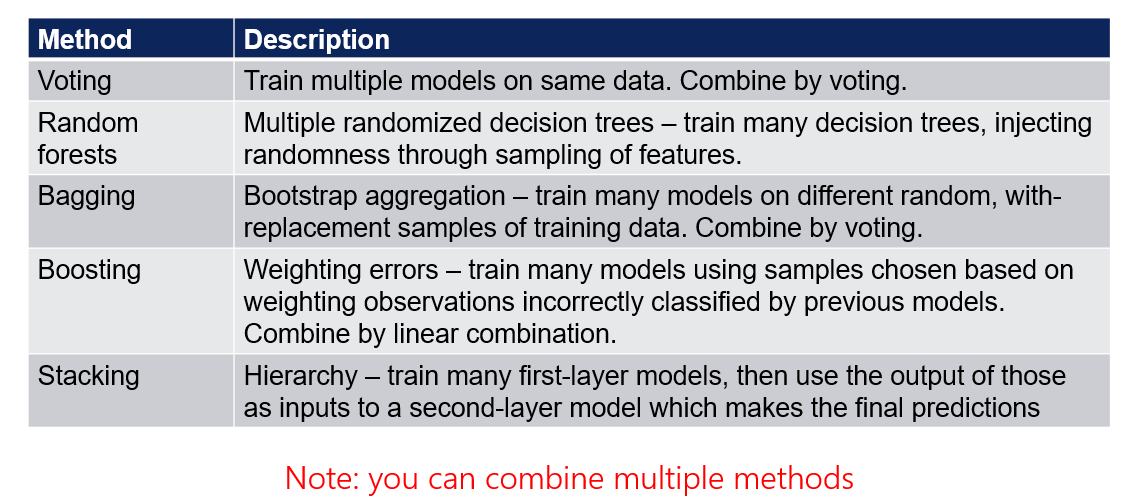

In [24]:
models = pd.DataFrame({
    'Model': ['Voting Hard', 'Voting Soft', 'Stacking', 'Bagging', 'Random Forest', 
              'AdaBoost', 'XGBoost'],
    'Score': [acc_vh, acc_vs, acc_sk,acc_bag, acc_rf, 
              acc_ada, acc_xg]})
models.round(decimals = 4).sort_values(by = 'Score', ascending = False)

,Model,Score
4,Random Forest,0.9111
6,XGBoost,0.9074
3,Bagging,0.9037
5,AdaBoost,0.9037
0,Voting Hard,0.8870
2,Stacking,0.8815
1,Voting Soft,0.8796


## Exercise 2
<div style="background-color:#DFF5DC; color:#14532D; border:1px solid #A5D6A7; border-left:5px solid #2E7D32; padding:15px; margin-bottom:20px; border-radius:4px;">
Compare the performance of the ensemble models to those from the individual models (table below). What trend do you find?
    </div>
    

Test accuracy of the individual models in Lab 9 (same wine data and split; the scaler is fitted on the training data only):

| Model | Test accuracy |
|---|---|
| RBF SVM (RandomizedSearchCV) | 0.8833 |
| RBF SVM (GridSearchCV) | 0.8796 |
| Neural Network | 0.8778 |
| RBF SVM | 0.8704 |
| Logistic Regression (Poly) | 0.8630 |
| KNN | 0.8556 |
| Linear SVM | 0.8185 |
| Logistic Regression | 0.8167 |
| Polynomial SVM | 0.8074 |


# Parameter tuning

You can apply the parameter tuning methods from Labs 08 and 9 to ensemble models. Below is an example of tuning the parameters for bagging. You can apply the same techniques to random forest and boosting.

For voting and stacking, usually it is more time-efficient to tune base models first (using GridSearchCV or RandomizedSearchCV) and then find the top models and place them into voting or stacking.

## Grid Search for Bagging

In [25]:
bag_clf = BaggingClassifier(estimator = DecisionTreeClassifier(random_state  = 1),
                            n_estimators = 100, 
                            random_state = 1)
parameters = {'estimator__max_depth': (20, 25, 30), 
              'n_estimators': (50, 100, 200)}
grid_bag = GridSearchCV(bag_clf, parameters, cv = 5, verbose = 3,
                        scoring = 'accuracy', return_train_score = True)
grid_bag.fit(X_train, y_train)

Fitting 5 folds for each of 9 candidates, totalling 45 fits


[CV 1/5] END estimator__max_depth=20, n_estimators=50;, score=(train=1.000, test=0.907) total time=   0.3s


[CV 2/5] END estimator__max_depth=20, n_estimators=50;, score=(train=1.000, test=0.898) total time=   0.3s


[CV 3/5] END estimator__max_depth=20, n_estimators=50;, score=(train=1.000, test=0.887) total time=   0.3s


[CV 4/5] END estimator__max_depth=20, n_estimators=50;, score=(train=1.000, test=0.882) total time=   0.3s


[CV 5/5] END estimator__max_depth=20, n_estimators=50;, score=(train=0.999, test=0.907) total time=   0.3s


... (37 outputs left out)

[CV 3/5] END estimator__max_depth=30, n_estimators=200;, score=(train=1.000, test=0.894) total time=   0.9s


[CV 4/5] END estimator__max_depth=30, n_estimators=200;, score=(train=1.000, test=0.880) total time=   0.9s


[CV 5/5] END estimator__max_depth=30, n_estimators=200;, score=(train=1.000, test=0.903) total time=   0.9s


GridSearchCV(cv=5,
             estimator=BaggingClassifier(estimator=DecisionTreeClassifier(random_state=1),
                                         n_estimators=100, random_state=1),
             param_grid={'estimator__max_depth': (20, 25, 30),
                         'n_estimators': (50, 100, 200)},
             return_train_score=True, scoring='accuracy', verbose=3)

In [26]:
print(grid_bag.best_params_)
print(grid_bag.best_score_)
y_grid_bag = grid_bag.predict(X_test)
accuracy_score(y_test, y_grid_bag)

{'estimator__max_depth': 20, 'n_estimators': 100}
0.8981481481481481


0.9111

# Bagging and Pipeline

In [27]:
bag_clf2 = Pipeline ([("poly", PolynomialFeatures(degree = 1)),
                     ("bag", BaggingClassifier(estimator = DecisionTreeClassifier(random_state  = 1),
                            n_estimators = 100, 
                            random_state = 1))])
parameters = {'bag__estimator__max_depth': (20, 25, 30), # We need to refer to pipeline step, then bagging parameter and finally decision tree parameters
              'bag__n_estimators': (50, 100, 200)}
grid_bag2 = GridSearchCV(bag_clf2, parameters, cv = 5, verbose = 3,
                        scoring = 'accuracy', return_train_score = True)
grid_bag2.fit(X_train, y_train)

Fitting 5 folds for each of 9 candidates, totalling 45 fits


[CV 1/5] END bag__estimator__max_depth=20, bag__n_estimators=50;, score=(train=1.000, test=0.900) total time=   3.2s


[CV 2/5] END bag__estimator__max_depth=20, bag__n_estimators=50;, score=(train=1.000, test=0.891) total time=   0.3s


[CV 3/5] END bag__estimator__max_depth=20, bag__n_estimators=50;, score=(train=1.000, test=0.884) total time=   0.3s


[CV 4/5] END bag__estimator__max_depth=20, bag__n_estimators=50;, score=(train=1.000, test=0.882) total time=   0.3s


[CV 5/5] END bag__estimator__max_depth=20, bag__n_estimators=50;, score=(train=0.999, test=0.903) total time=   0.3s


... (37 outputs left out)

[CV 3/5] END bag__estimator__max_depth=30, bag__n_estimators=200;, score=(train=1.000, test=0.894) total time= 3.0min


[CV 4/5] END bag__estimator__max_depth=30, bag__n_estimators=200;, score=(train=1.000, test=0.882) total time=   1.5s


[CV 5/5] END bag__estimator__max_depth=30, bag__n_estimators=200;, score=(train=1.000, test=0.905) total time=   1.4s


GridSearchCV(cv=5,
             estimator=Pipeline(steps=[('poly', PolynomialFeatures(degree=1)),
                                       ('bag',
                                        BaggingClassifier(estimator=DecisionTreeClassifier(random_state=1),
                                                          n_estimators=100,
                                                          random_state=1))]),
             param_grid={'bag__estimator__max_depth': (20, 25, 30),
                         'bag__n_estimators': (50, 100, 200)},
             return_train_score=True, scoring='accuracy', verbose=3)

In [28]:
print(grid_bag2.best_params_)
print(grid_bag2.best_score_)
y_grid_bag = grid_bag2.predict(X_test)
accuracy_score(y_test, y_grid_bag)

{'bag__estimator__max_depth': 20, 'bag__n_estimators': 100}
0.8976851851851851


0.9148

# Claude Code: Context and Memory
The agent does not remember the way you do. Everything it can use at this moment sits in its **context window**: the instructions and tools it starts with, your `CLAUDE.md` file, the names of your skills, and the conversation so far. When the window fills up, older detail has to be summarized or dropped.

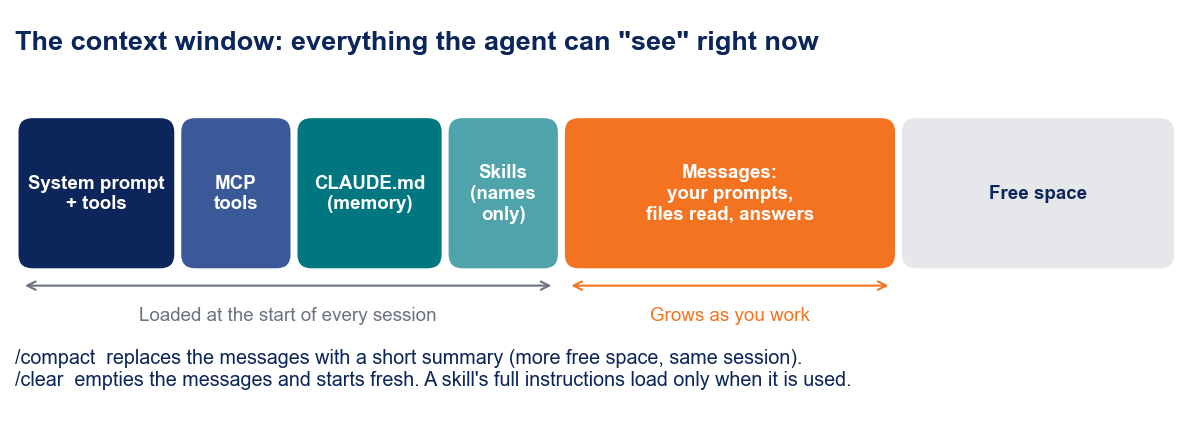

## Step 1: Look at Your Context Window
**Start a fresh session.** In the VS Code terminal, run `pwd` and check that the last folder is `comm4259-work`. Then type `claude` and press Enter. If Claude Code is already running, type `/clear` first so the session starts empty.

**Take the first snapshot.** Type `/context` and press Enter. You will see a grid of small icons on the left and a list on the right. Each icon is a slice of the context window, and its color matches a category in the list. Empty squares are free space. Read these lines:

- **The total**, at the top right, for example `37.4k/1m tokens (4%)`. The first number is how much is used. The number after the slash is the size of the whole window (200k or 1m, depending on your plan). A token is a piece of a word; 1,000 tokens is roughly 750 English words.
- **The categories** under *Estimated usage by category*. What they mean:

| Category | What it is |
|---|---|
| System prompt, System tools | Claude Code's own instructions and its built-in tools (read files, run commands). Always loaded. |
| MCP tools, MCP server instructions | The tools from MCP servers you connected, such as course-db in Lab 09. |
| Memory files | Your `CLAUDE.md` files, read at the start of every session. |
| Skills | The name and one-line description of each skill. The full instructions load only when a skill is used. |
| Messages | Your prompts, the files the agent read, and its answers. This is the part that grows as you work. |
| Free space | What is left. When it runs low, Claude Code compacts the conversation automatically (the *Autocompact buffer*). |

Fill in the first column of the table below.

**Take the second snapshot.** Paste this prompt and wait for the answer:

```
Read lab_10/Lab_10-Ensemble.ipynb and list the ensemble methods it uses, in five bullets. Do not change any files.
```

Type `/context` again and fill in the second column.

| | Snapshot 1: fresh session | Snapshot 2: after reading the notebook |
|---|---|---|
| Total used (e.g., 37.4k) | | |
| Messages | | |
| Memory files | | |
| Skills | | |
| Free space | | |

Answer:
1. Which category grew the most between the two snapshots, and by about how many tokens?
2. Why did it grow? (Hint: what did the agent have to put into its context to answer your prompt?)
3. Which categories did not change? Why not?

Your answers:
1.
2.
3.

## Step 2: What the Agent Remembers
A rule typed in the chat lives only in the context window. A rule in `CLAUDE.md` is a file on disk, so it is read again at the start of every session.

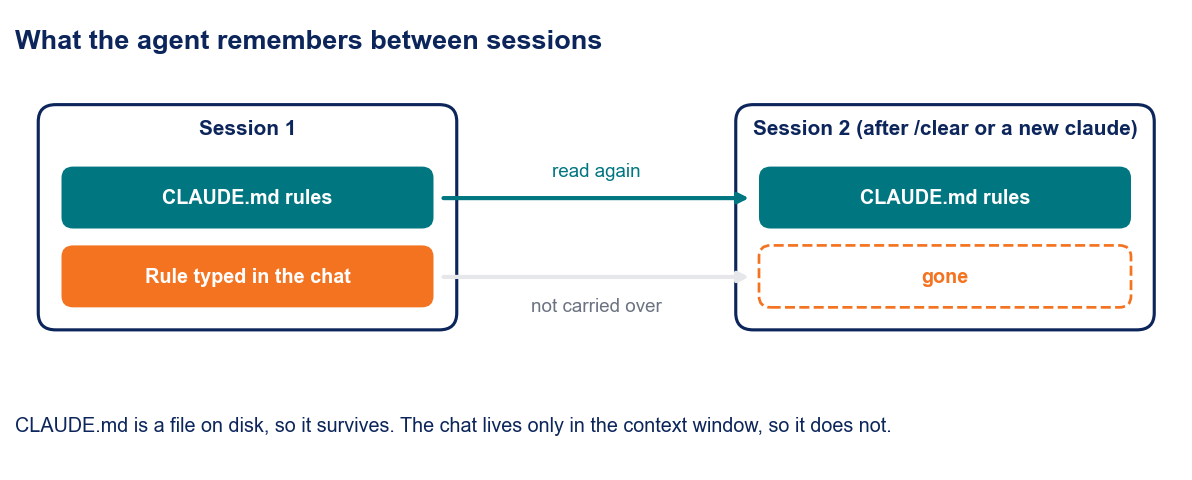

Test it:
1. Type this rule and press Enter: *For the rest of this session, answer every question in exactly three bullet points.*
2. Ask: *What does a random forest add to bagging?* Check that the answer has three bullets.
3. Type `/clear`. This empties the messages but keeps Claude Code running.
4. Ask the same question again: *What does a random forest add to bagging?*

| Test | Three bullets? (Yes/No) |
|---|---|
| Step 2: right after you gave the rule | |
| Step 4: after `/clear` | |

Answer:
1. Did the rule survive `/clear`? Use the diagram to explain why.
2. If you wanted the agent to follow this rule in every session, where would you put it?

Your answers:
1.
2.

## Step 3: Map Your Context With a Skill
`lab_10` includes a small course skill, `context-map`, that draws what is in the agent's context window and explains what survives `/compact`, `/clear`, and a new session. It only reads; it does not change any files.

1. Install the skill. Paste this prompt and answer Yes when it asks to create the file:

```
Copy lab_10/context-map-SKILL.md to .claude/skills/context-map/SKILL.md inside comm4259-work. Do not change anything else.
```

2. Type `/exit`, then type `claude --continue` in the terminal. Claude Code loads skills only when it starts, so it has to restart to see the new one; `--continue` reopens the same conversation, so nothing from Steps 1 and 2 is lost. Type `/context`, and then paste:

```
/context-map Use the /context numbers above.
```

3. Open `.claude/skills/context-map/SKILL.md` in VS Code and read it. A skill is just written instructions, so you can always check what one will do before you use it.

Answer:
1. Which part of the map survives `/clear`, and which part does not? Does that match the diagram in Step 2?
2. In one sentence: when would you use `/compact`, and when would you use `/clear`?
3. What is one rule you would put in your `CLAUDE.md` for this course, and why does it belong there rather than in a prompt?

Your answers:
1.
2.
3.

Type `/exit` when you are done. If you still have the Lab 9 course database server connected, you can remove it from the terminal (not inside a Claude session) with `claude mcp remove course-db`.

# Before Class Ends
Save this notebook (Cmd+S or Ctrl+S). Then, from `comm4259-work`, commit and push your work:

```
git add .
git commit -m "Lab 10: ensembles, context and memory"
git push
```